# P1 · Exploración y lectura del baseline

**Saúl Salgado Ortega · Equipo 49 · TC5061**

P1 pronostica salidas por **estación y hora**, emitiendo a las 00:00 las 24 horas del día. Este notebook inspecciona resúmenes y artefactos agregados. La ingesta, las variables, la evaluación y el registro de MLflow están en `mibici_ml/` y se ejecutan desde terminal.

Antes de ejecutar todas las celdas:

```powershell
python -m mibici_ml.dataset
python -m mibici_ml.modeling.demand
```

Consulta `references/P1_propuesta_y_resultados.md` para la formulación completa. Este notebook no expone datos por viaje ni datos personales.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

# Funciona desde la raíz del proyecto o desde notebooks/.
PROJECT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / 'mibici_ml' / 'config.py').is_file()),
    None,
)
if PROJECT is None:
    raise FileNotFoundError('Abre este notebook dentro del repositorio MiBici.')

TABLES = PROJECT / 'reports' / 'tables'
FIGURES = PROJECT / 'reports' / 'figures'
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True})
print('Entradas: tablas y figuras agregadas de reports/.')


Entradas: tablas y figuras agregadas de reports/.


## 1. Procedencia: EDA anterior frente a la ejecución nueva

El EDA del equipo resume los doce meses completos antes de la nueva preparación de P1. Sus totales permiten reconocer patrones, pero no son automáticamente los conteos del conjunto limpio ni la cohorte evaluada. Las métricas de esta ejecución deben interpretarse con `p1_quality.json`.

Fuentes: [MiBici](https://mibici.net/es/datos-abiertos/) y catálogo de septiembre de 2026. El manifiesto conserva URLs, conteos y SHA-256; su versión se registra en MLflow.

In [2]:
previous = json.loads((TABLES / 'resumen.json').read_text(encoding='utf-8'))
display(pd.DataFrame([
    {'concepto': 'Meses en el EDA anterior', 'valor': len(previous['meses'])},
    {'concepto': 'Viajes crudos en el EDA anterior', 'valor': previous['viajes_12_meses']},
    {'concepto': 'Estaciones del catálogo', 'valor': previous['estaciones_catalogo']},
    {'concepto': 'Estaciones con salidas en el EDA anterior', 'valor': previous['estaciones_con_salidas_12m']},
]))

quality_path = TABLES / 'p1_quality.json'
if not quality_path.is_file():
    raise FileNotFoundError('Falta p1_quality.json. Ejecuta la ingesta y el experimento P1.')
quality = json.loads(quality_path.read_text(encoding='utf-8'))
# Solo metadatos y conteos: este artefacto no contiene registros de usuarios.
print(json.dumps(quality, indent=2, ensure_ascii=False))


,concepto,valor
0,Meses en el EDA anterior,12
1,Viajes crudos en el EDA anterior,4497877
2,Estaciones del catálogo,484
3,Estaciones con salidas en el EDA anterior,471


{
  "data_version": "0f000bd5e6563196d7c1133e119024e4e864f6325752e4f6b48e40011895d1a3",
  "raw_rows": 4497877,
  "clean_rows": 4493328,
  "months": [
    "2025_10",
    "2025_11",
    "2025_12",
    "2026_01",
    "2026_02",
    "2026_03",
    "2026_04",
    "2026_05",
    "2026_06",
    "2026_07",
    "2026_08",
    "2026_09"
  ],
  "observed_origin_stations": 471,
  "panel_rows": 4125960,
  "coverage": {
    "train": {
      "known_station_hours": 2430096,
      "evaluated_station_hours": 2160408,
      "excluded_warmup_hours": 269688,
      "n_stations": 382,
      "zero_fraction": 0.5442296084813609
    },
    "val": {
      "known_station_hours": 673656,
      "evaluated_station_hours": 629424,
      "excluded_warmup_hours": 44232,
      "n_stations": 455,
      "zero_fraction": 0.5644446350949439
    },
    "test": {
      "known_station_hours": 338856,
      "evaluated_station_hours": 336480,
      "excluded_warmup_hours": 2376,
      "n_stations": 470,
      "zero_fraction": 0.

## 2. ¿Existe un patrón semanal y horario?

Inspeccionamos el perfil ya preparado por el equipo. La tabla contiene **totales agregados** por día de la semana y hora, no promedios por estación. Es exploración histórica del conjunto completo y no se usa para ajustar un modelo ni construir variables del baseline.

Una regularidad semanal motiva comparar la misma hora de la semana anterior con una media de cuatro semanas. El horario publicado actualmente limita las salidas a 05:00–00:59; muchos ceros de madrugada pueden ser estructurales. No se presupone que esa página pruebe el horario de todos los meses históricos.

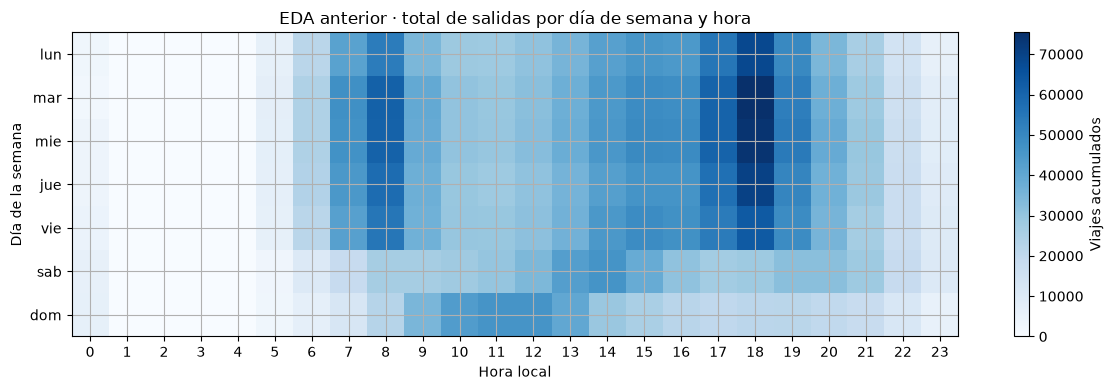

In [3]:
profile = pd.read_csv(TABLES / 'perfil_dia_hora.csv', index_col=0)
profile.columns = profile.columns.astype(int)
fig, ax = plt.subplots(figsize=(12, 4))
heatmap = ax.imshow(profile.to_numpy(), aspect='auto', cmap='Blues')
ax.set_xticks(range(24), range(24))
ax.set_yticks(range(len(profile)), profile.index)
ax.set_xlabel('Hora local')
ax.set_ylabel('Día de la semana')
ax.set_title('EDA anterior · total de salidas por día de semana y hora')
fig.colorbar(heatmap, ax=ax, label='Viajes acumulados')
fig.tight_layout()
plt.show()


## 3. ¿El volumen cambia a través del tiempo?

Esta serie diaria es un agregado de toda la red. Ayuda a detectar cambios, días atípicos y diferencias entre periodos. No sustituye la granularidad estación-hora utilizada por P1.

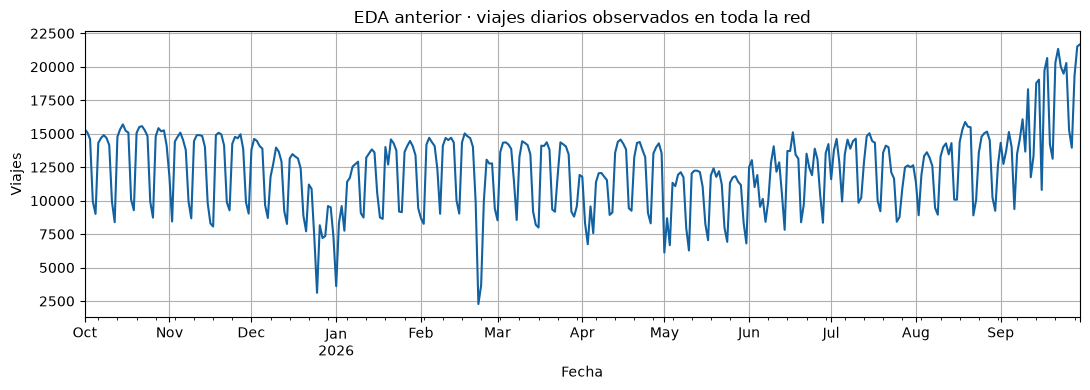

In [4]:
daily = pd.read_csv(TABLES / 'volumen_diario.csv', parse_dates=['Inicio_del_viaje'])
ax = daily.plot(x='Inicio_del_viaje', y='viajes', legend=False, color='#1261a0')
ax.set_title('EDA anterior · viajes diarios observados en toda la red')
ax.set_xlabel('Fecha')
ax.set_ylabel('Viajes')
plt.tight_layout()
plt.show()


## 4. Protocolo del experimento

| Decisión | Implementación |
|---|---|
| Objetivo | Salidas válidas en `[hora, hora + 1 h)` por estación |
| Emisión | Medianoche, 24 predicciones por estación para el día que inicia |
| Historia inicial | Octubre de 2025–junio de 2026 |
| Validación | Julio–agosto de 2026 |
| Prueba | Septiembre de 2026 |
| Baselines | Rezago de 168 h; media de cuatro rezagos semanales |
| Comparación | Misma cohorte con 28 días completos de historia |
| Selección | Menor WAPE de validación; septiembre no ajusta el modelo |

El backtest avanza diariamente. Las observaciones de días previos de validación/prueba son historia disponible; las del día pronosticado no lo son. La serie se conserva horaria y regular. No se imputan ceros anteriores a la primera actividad observada.

La propuesta incluye `PoissonRegressor` y `HistGradientBoostingRegressor(loss='poisson')` para una siguiente iteración. No se confunden modelos propuestos con runs ejecutados.

## 5. Métricas observadas

**MAE:** error medio absoluto en viajes por estación-hora. **WAPE:** error absoluto total dividido entre viajes observados, expresado como razón. **RMSE:** mayor penalización a errores grandes. **Bias:** predicción menos valor real; un valor negativo indica subestimación.

No usar MAPE como referencia principal: hay horas con cero salidas. WAPE no es un porcentaje de aciertos; `0.50` significa error absoluto agregado equivalente al 50 % del volumen real. La comparación requiere idéntica cohorte.

In [5]:
metrics_path = TABLES / 'p1_metrics.csv'
if not metrics_path.is_file():
    raise FileNotFoundError('Falta p1_metrics.csv. Ejecuta python -m mibici_ml.modeling.demand.')
metrics = pd.read_csv(metrics_path)
required = {'baseline', 'split', 'mae', 'rmse', 'wape', 'bias', 'n_rows', 'n_stations', 'actual_total'}
missing = required.difference(metrics.columns)
if missing:
    raise ValueError(f'Faltan columnas de métricas: {sorted(missing)}')
display(metrics.sort_values(['split', 'wape']).round(4))


,baseline,split,mae,rmse,wape,bias,actual_total,n_rows,n_stations
3,mean_4weeks,test,0.8806,1.7412,0.6073,-0.2236,487915.0,336480,470
2,seasonal_168h,test,1.0297,2.1127,0.7101,-0.1173,487915.0,336480,470
1,mean_4weeks,val,0.8011,1.5052,0.6567,-0.0160,767908.0,629424,455
0,seasonal_168h,val,0.9287,1.8594,0.7612,-0.0049,767908.0,629424,455


In [6]:
validation = metrics.loc[metrics['split'].isin(['val', 'validation'])].copy()
if validation.empty:
    raise ValueError('El archivo no contiene métricas de validación.')
selected = validation.sort_values(['wape', 'mae', 'baseline']).iloc[0]
print(f"Referencia elegida con validación: {selected['baseline']}")
print(f"MAE de validación: {selected['mae']:.4f} viajes/estación-hora")
print(f"WAPE de validación: {selected['wape']:.2%}")
print('La elección anterior no utiliza las métricas de septiembre.')


Referencia elegida con validación: mean_4weeks
MAE de validación: 0.8011 viajes/estación-hora
WAPE de validación: 65.67%
La elección anterior no utiliza las métricas de septiembre.


## 6. Artefactos del código de entrenamiento

Las figuras siguientes las genera el módulo y se registran también en MLflow. La gráfica de totales diarios puede mostrar cancelación entre errores de distintas estaciones; por ello se acompaña de las métricas a granularidad estación-hora y un ejemplo local. Una sola estación ilustra el comportamiento, pero no representa a toda la red.

P1_error_comparison.png


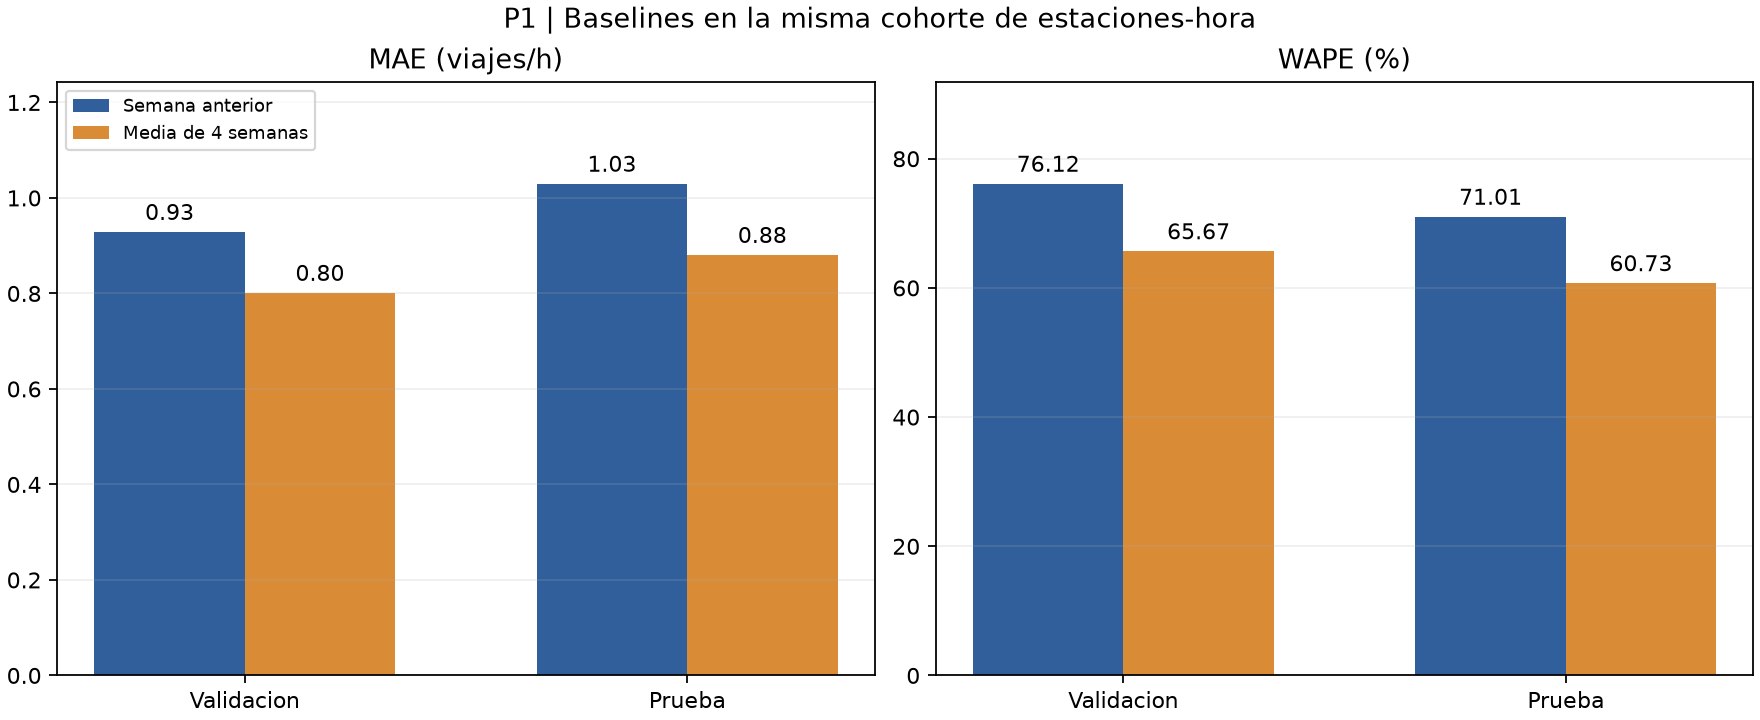

P1_daily_totals.png


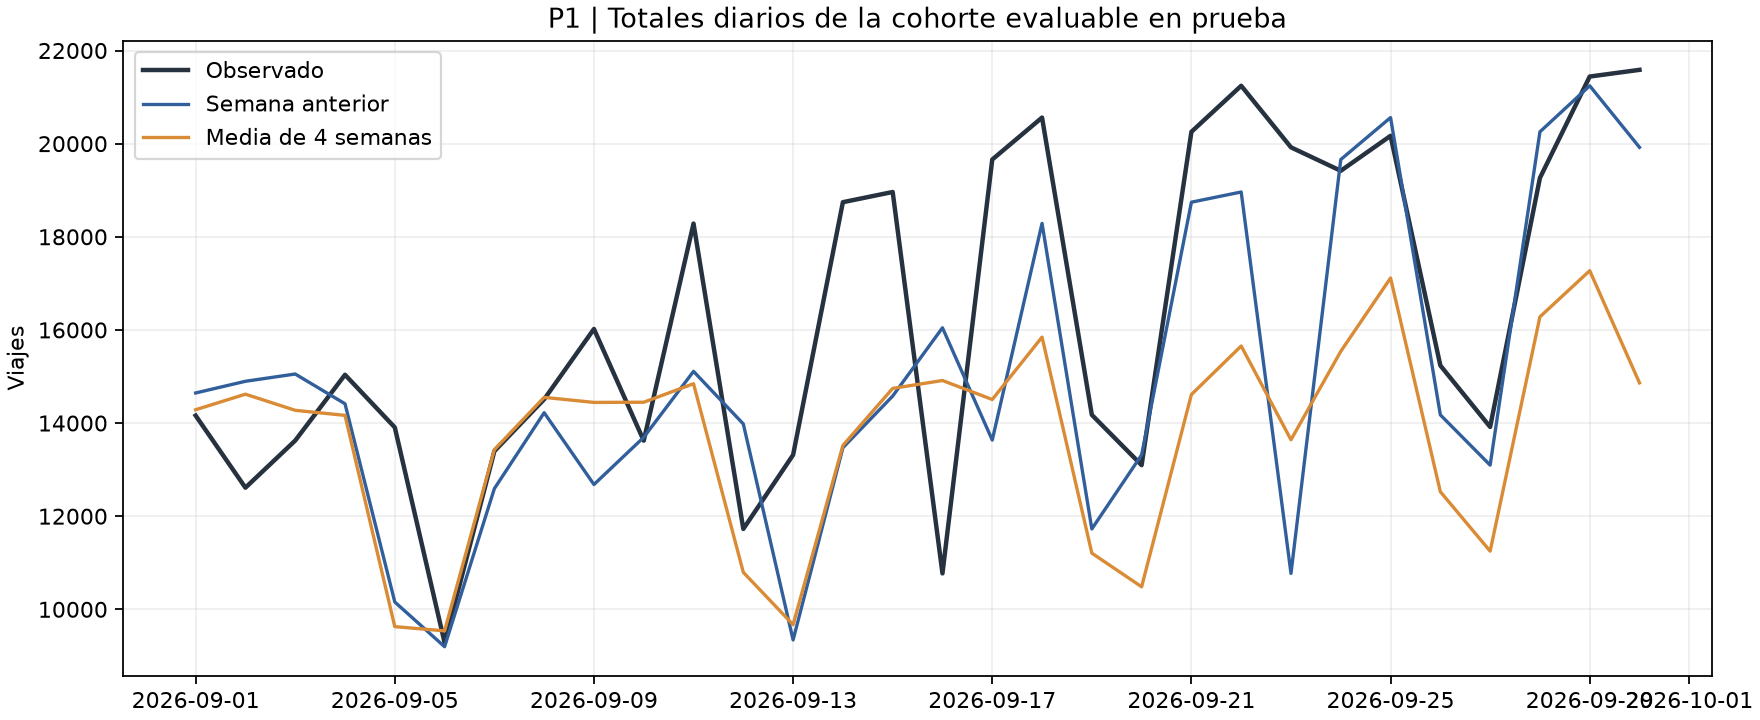

P1_station_example.png


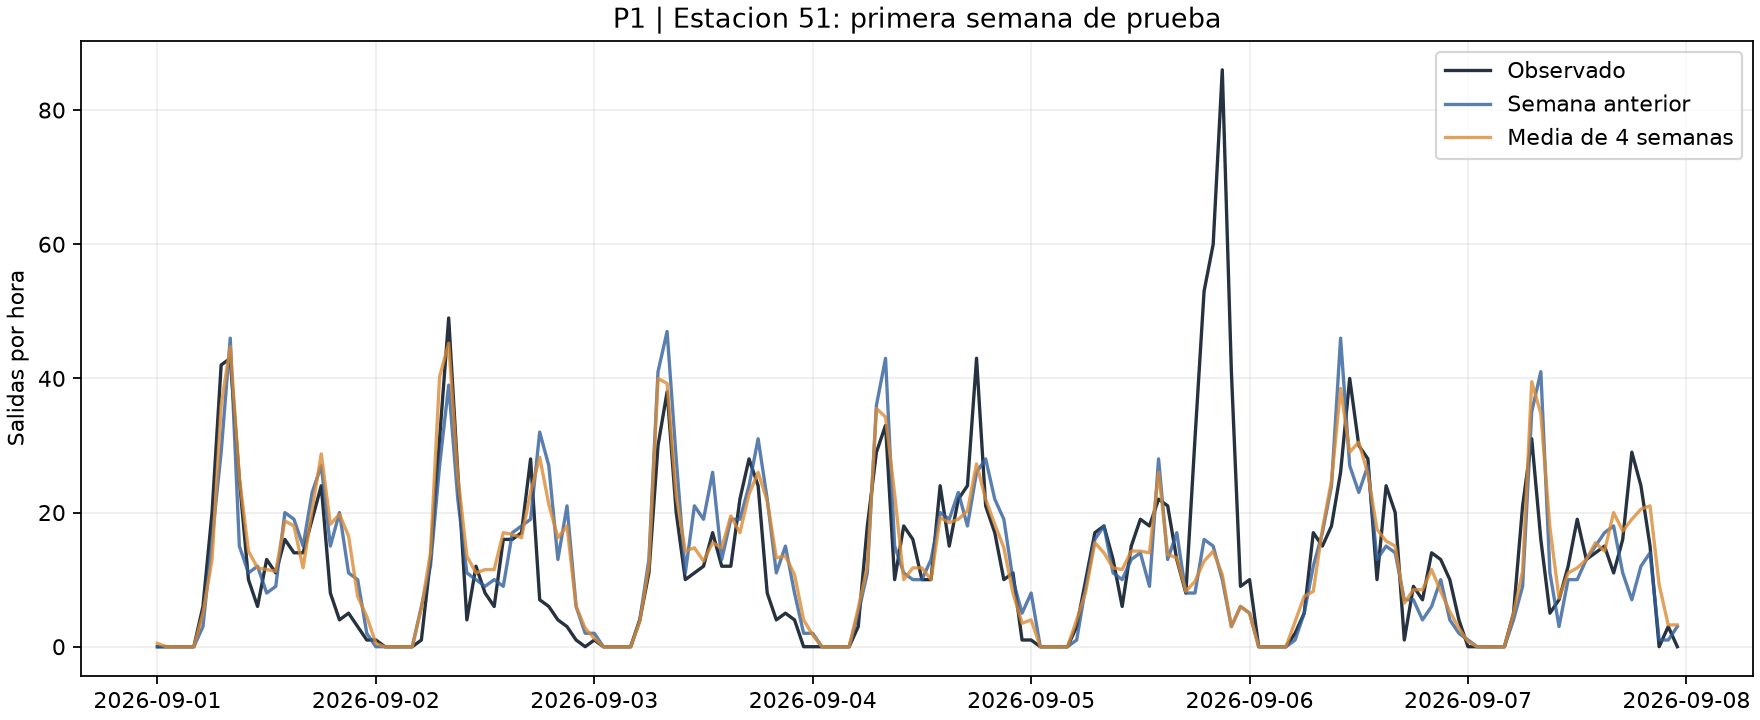

In [7]:
figure_names = [
    'P1_error_comparison.png',
    'P1_daily_totals.png',
    'P1_station_example.png',
]
for name in figure_names:
    path = FIGURES / name
    if path.is_file():
        print(name)
        display(Image(filename=str(path)))
    else:
        print(f'Pendiente de generar: {name}')


## 7. Interpretación y límites

- Verifica en `p1_quality.json` cuántas filas/estaciones se evalúan, la versión y las exclusiones. El catálogo completo no equivale a la cohorte con historia suficiente.
- Revisa si el sesgo señala subestimación, especialmente cuando sube el volumen. La media de cuatro semanas puede suavizar demasiado una tendencia reciente.
- Un cero después de la primera actividad puede reflejar baja demanda o una estación cerrada/sin bicicletas. Los viajes permiten modelar salidas observadas, no demanda insatisfecha.
- La primera salida observada no prueba la inauguración; tampoco el catálogo actual describe todas las capacidades históricas.
- Sin clima, festividades, eventos, stock y operación histórica, estos son baselines iniciales. Las métricas no prueban por sí solas una mejora operativa de la flota.
- Los CSV mensuales hacen viable el backtest. Un servicio diario requerirá datos disponibles con esa frecuencia.

Para la evidencia de la actividad, abrir el experimento `mibici-equipo49` y capturar lista, detalle, artefacto y comparación de runs. No versionar `data/`, `mlruns/`, `mlartifacts/`, `.env` o modelos serializados.

## Referencias

- MiBici. (s. f.). [Datos abiertos](https://mibici.net/es/datos-abiertos/) y [términos y condiciones](https://mibici.net/es/termino-y-condiciones/). Consulta: 18 de octubre de 2026.
- The scikit-learn developers. (s. f.). [Lagged features for time series forecasting](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html).
- The scikit-learn developers. (s. f.). [Metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html).
- MLflow. (s. f.). [ML experiment tracking](https://mlflow.org/docs/latest/ml/tracking/).
